# Reconstruction de signe ODMR sur FeGa

La mesure **2026-05-25-10-27-11** acquise sous environ 10 mT est analysée
par ajustement lorentzien à un pic, annotation du signe, graph cut,
raffinement continu et reconstruction vectorielle par inversion de Fourier.
La mesure **2026-05-25-23-05-22**, acquise sous environ 50 mT, fournit une
comparaison descriptive des cartes de champ projeté.

Les fonctions de traitement proviennent de `helpers.py`, `fits.py`,
`odmr_sign_unwrap.py` et `odmr_measurement_helpers.py`.
L'annotation à la souris nécessite le backend Jupyter `ipympl`.
L'annotation par coordonnées constitue une alternative non interactive.
Les cellules sont organisées selon les étapes du traitement ; la validation
des seeds intervient après leur annotation ou leur rechargement.

## Hypothèses physiques

La conversion $A=|f_0-D|/\gamma_{NV}$ repose sur l'approximation linéaire
avec $D=2.87$ GHz et $\gamma_{NV}=28.024$ GHz/T. Les champs transverses,
la température et les contraintes peuvent introduire un biais, notamment
près du champ nul. Une résonance unique ne détermine pas le signe de la
projection : cette information est apportée par les seeds.

La norme du champ du magnet n'est pas assimilée à une projection NV connue.
L'état magnétique peut évoluer entre les mesures à 10 et 50 mT ; la seconde
mesure ne constitue donc pas une vérité terrain pour la reconstruction du signe.

In [14]:
%matplotlib inline
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import ndimage as ndi
from helpers import load_df1, plot_contrast_argmin, reconstruct_B_from_Bparallel_Fourier
from fits import plot_fits_on_spectrograms
from odmr_measurement_helpers import (fit_spectrum, plot_field,
                                      plot_reconstructed_B_quiver_with_zoom)
import odmr_sign_unwrap as osu

ROOT = Path.cwd()
assert (ROOT / 'fits.py').exists(), 'Le répertoire courant doit contenir les modules du projet.'
DATE = '2026-05-25-10-27-11'
DATE_COMPARE = '2026-05-25-23-05-22'
DATA = ROOT / 'Datas2'
OUT = ROOT / 'outputs' / ('sign_unwrap_' + DATE)
OUT.mkdir(parents=True, exist_ok=True)
INPUT_SEED_PATH = ROOT / 'saved_seed_masks' / ('seeds_' + DATE + '.npz')
SEED_PATH = OUT / ('seeds_' + DATE + '.npz')
SEED_MODE = 'saved'  # 'saved', 'coordinates', or 'interactive'.
D_HZ = 2.87e9
GAMMA_HZ_PER_T = 28.024e9
NORMALIZE, SMOOTH_WIN = True, 3
# Rognage du spectre autour du zero-field splitting pour isoler une résonance.
CROP_AROUND_D = True
KEEP_GLOBAL_MIN = False
# Orientation instrumentale; transformation vers le repère image explicite ci-dessous.
NV_THETA_DEG, NV_PHI_DEG = 54.75, 0.0
IMAGE_AXIS_SIGNS = (-1, +1, +1)  # X décroît vers la droite; Y croît vers le bas.
FOURIER_KW = dict(lambda0=1e-8, p=10, alpha=1.0, dc_mode="zero")
REFINE_KW = dict(tau_mT=0.15, mu_data=1., lambda_lap=0.53,
                 lambda_anchor=0.05, lambda_seed=10., data_weight_floor=0.05,
                 maxiter=300)
GC_KW = dict(lambda_pair=1., connectivity=4, normalize_percentile=95,
             seed_cost=1e6)
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11})

## 1. Chargement et inspection des spectres

`load_df1` applique la rotation des indices utilisée par QZabre. Les cartes,
grilles et seeds partagent ensuite le même repère image.

Les paramètres `center_i`, `center_j` et `half_small` définissent la région
inspectée. Un demi-côté de 2 correspond à une grille de 5 × 5 spectres hors
des bords de la carte. `plot_contrast_argmin` affiche la carte entière avec
le rectangle de cette région avant les fits locaux à un pic.

L'inspection locale est indépendante du traitement des deux cartes complètes.
Les fits complets conservent les échecs sous forme de NaN et signalent les centres
proches d'un bord de fenêtre. La grille QZabre peut remplacer un fit échoué par
le minimum brut du spectre. Les deux traitements partagent la normalisation,
le lissage et les paramètres de rognage autour de D.

In [15]:
scans = {}
for date in (DATE, DATE_COMPARE):
    folder = DATA / (date + '-odmr_hardware')
    meta = json.loads((folder / 'imageMeta.json').read_text(encoding='utf-8'))
    df = load_df1(folder / 'seq0' / 'eval' / 'odmr.txt', DOWNCAST_INT=True)
    shape = (int(df.i.max()) + 1, int(df.j.max()) + 1)
    scans[date] = dict(meta=meta, df=df, shape=shape)
    print(date, shape, 'Bext [mT] =', meta['vectorMagnetSettings']['field_strength'],
          'taille [µm] =', np.array(meta['rect']['size']) * 1e6,
          'hauteur [nm] =', meta['scanHeightControl']['scanDistance'] * 1e9)

2026-05-25-10-27-11 (110, 110) Bext [mT] = 9.999399831989919 taille [µm] = [7. 7.] hauteur [nm] = 150.0
2026-05-25-23-05-22 (110, 110) Bext [mT] = 49.99978672954516 taille [µm] = [7. 7.] hauteur [nm] = 150.0


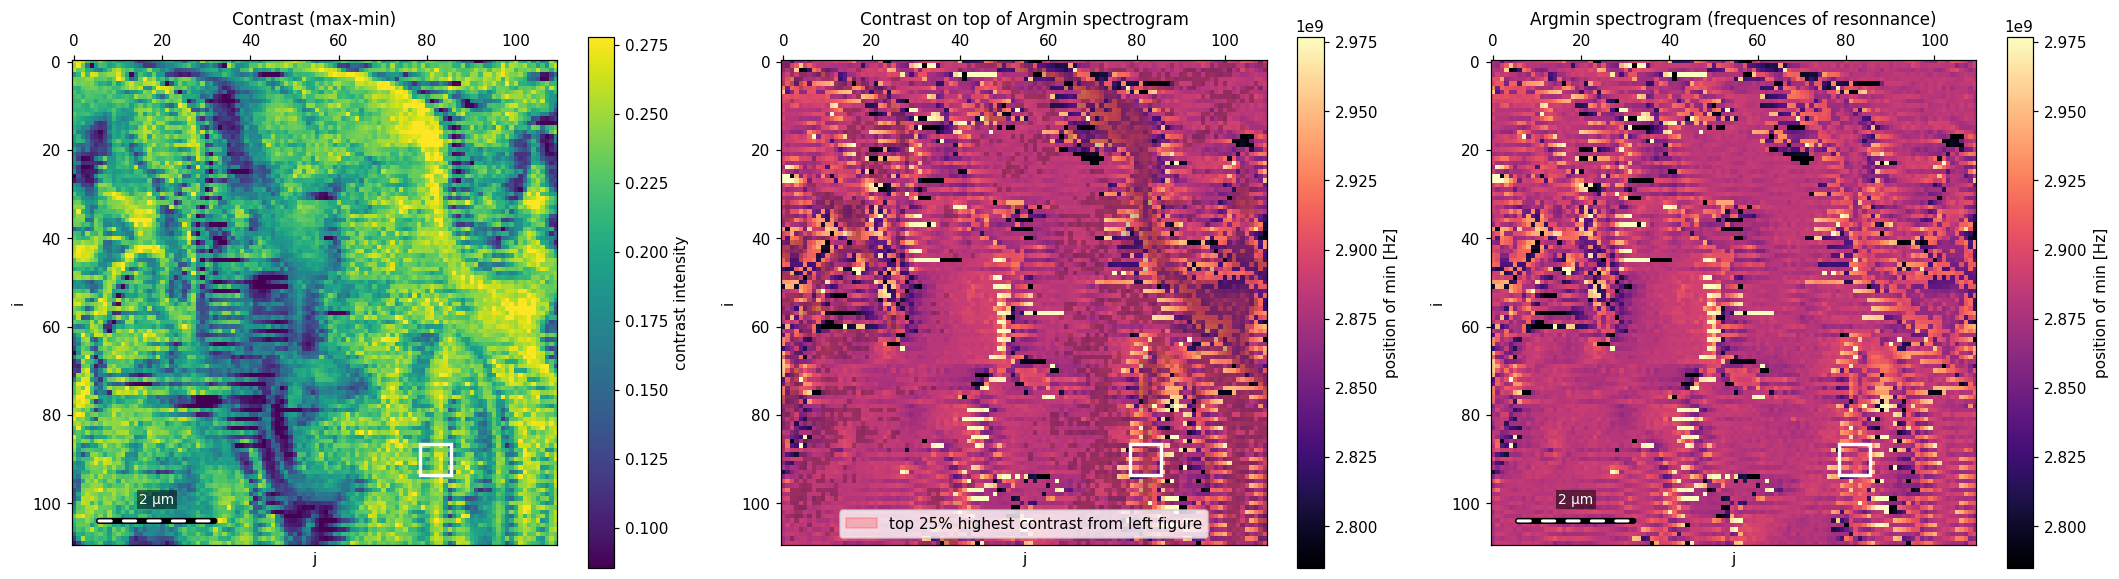

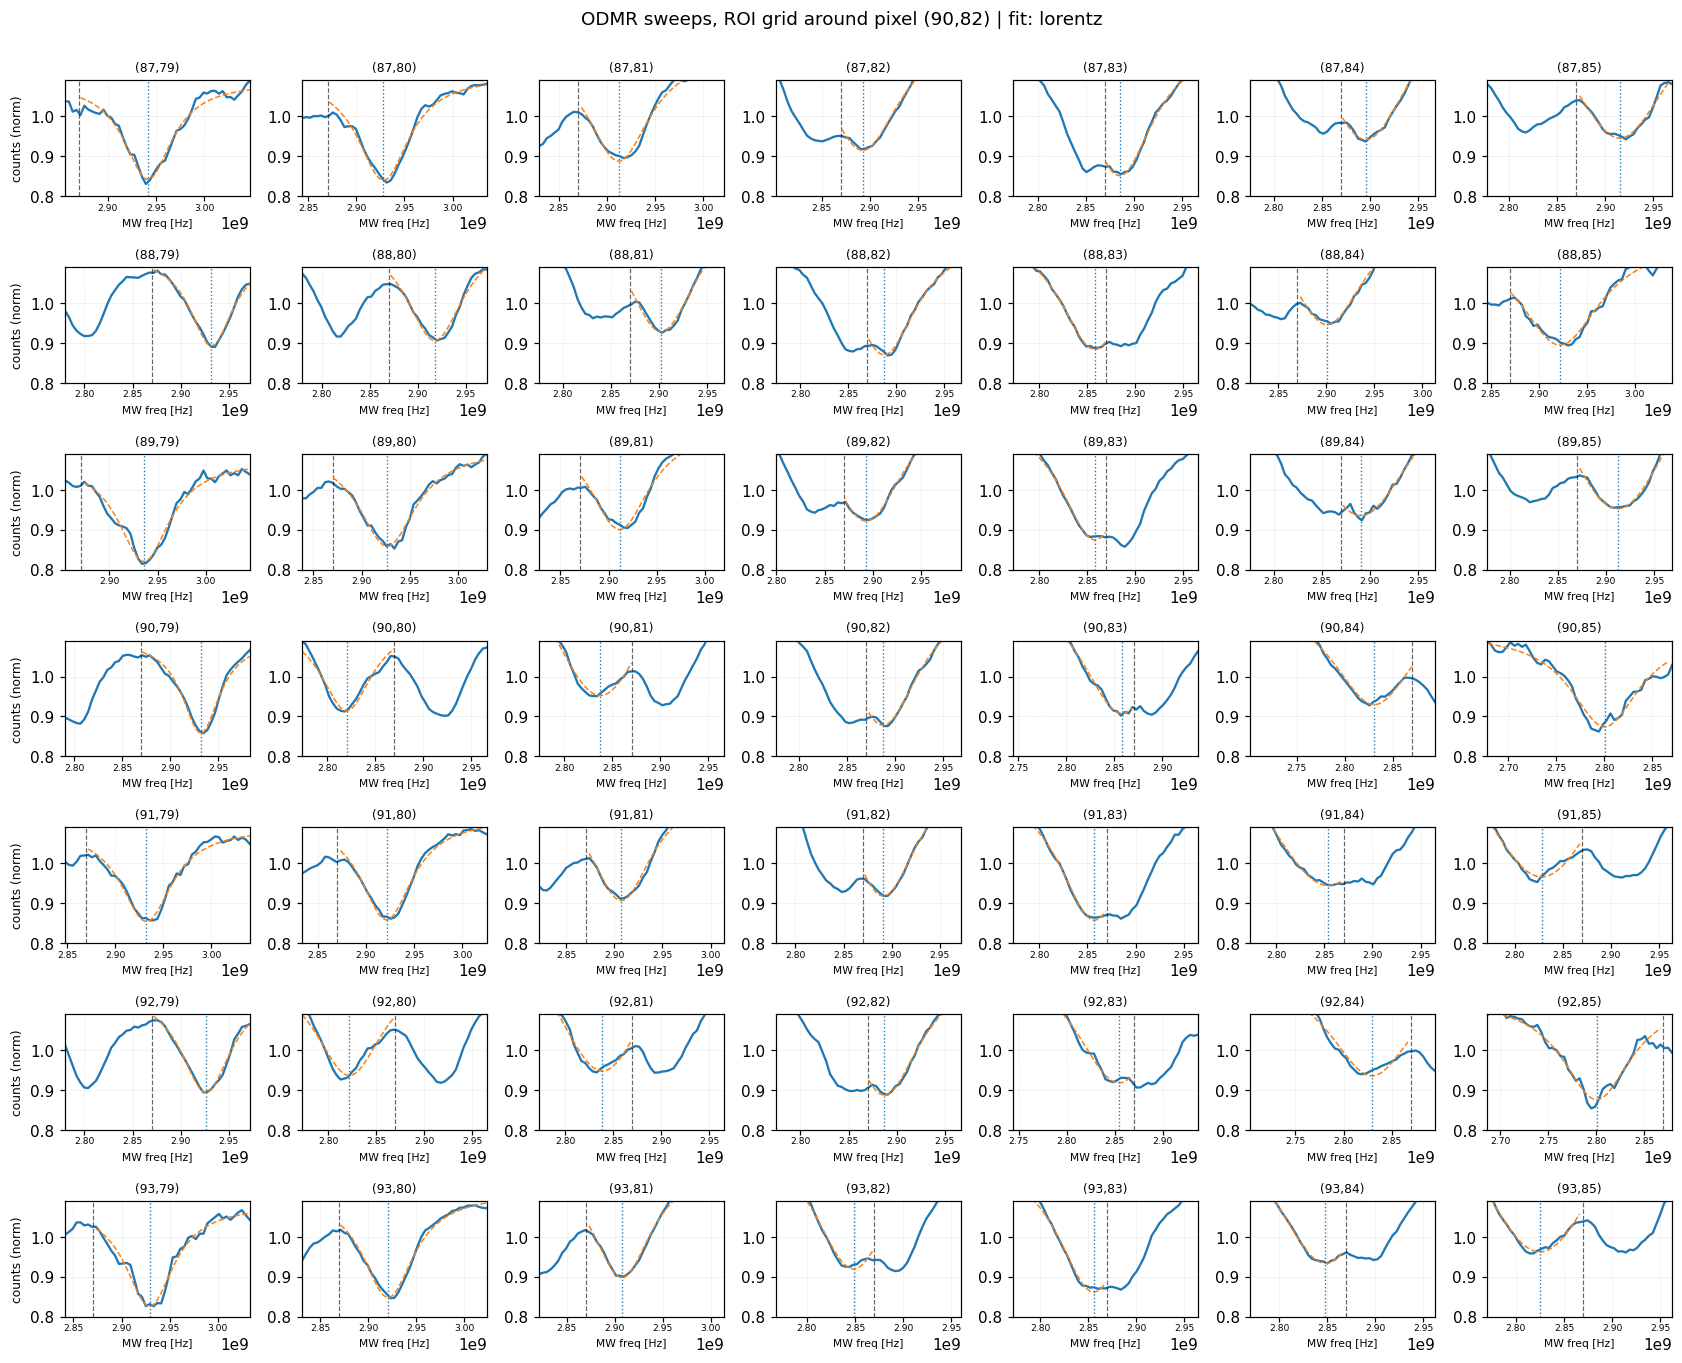

     i   j           xv1           xv2      mode subset
0   87  79  2.798314e+09  2.798314e+09  one_peak  right
1   87  80  2.811789e+09  2.811789e+09  one_peak  right
2   87  81  2.827649e+09  2.827649e+09  one_peak  right
3   87  82  2.847323e+09  2.847323e+09  one_peak  right
4   87  83  2.854954e+09  2.854954e+09  one_peak  right
5   87  84  2.844409e+09  2.844409e+09  one_peak  right
6   87  85  2.824741e+09  2.824741e+09  one_peak  right
7   88  79  2.807905e+09  2.807905e+09  one_peak  right
8   88  80  2.822123e+09  2.822123e+09  one_peak  right
9   88  81  2.837747e+09  2.837747e+09  one_peak  right
10  88  82  2.852563e+09  2.852563e+09  one_peak  right
11  88  83  2.857892e+09  2.857892e+09  one_peak   left
12  88  84  2.839222e+09  2.839222e+09  one_peak  right
13  88  85  2.817941e+09  2.817941e+09  one_peak  right
14  89  79  2.804046e+09  2.804046e+09  one_peak  right
15  89  80  2.813218e+09  2.813218e+09  one_peak  right
16  89  81  2.828558e+09  2.828558e+09  one_peak

<Figure size 704x528 with 0 Axes>

In [16]:
# Centre et demi-côté de la région de spectres étudiée.
center_i = 90
center_j = 82
half_small = 3  # (2*half_small+1)^2 = 49 spectra; use 2 for a 5x5 grid.
df = scans[DATE]['df']
assert half_small >= 0 and int(half_small) == half_small
assert 0 <= center_i < scans[DATE]['shape'][0] and 0 <= center_j < scans[DATE]['shape'][1]
# Les bornes inclusives suivent les pixels réellement présents dans la grille.
n_i, n_j = scans[DATE]['shape']
roi_box = (max(0, center_i-half_small), min(n_i-1, center_i+half_small),
           max(0, center_j-half_small), min(n_j-1, center_j+half_small))
plot_contrast_argmin(
    df, NORMALIZE, SMOOTH_WIN,
    center_i, center_j, half=max(n_i, n_j),
    use_processed=True, grid=False, panel_size=(6.5, 5.5),
    roi_box=roi_box,
    Size_um=scans[DATE]['meta']['rect']['size'][0]*1e6,
    scalebar=True,
)

f_local = plot_fits_on_spectrograms(
    df, NORMALIZE, SMOOTH_WIN,
    center_i, center_j, half=half_small, share_axes=True,
    per_panel_x=True,
    mark_two_min=True,
    fit_model="lorentz",
    initialisation="symmetric",
    maponly_=False,
    freq_mode="frequences_odmr",
    min_curve_amp=0.1, min_peak_amp=0.2, maxcurve=1,
    min_separation_peak=0.02, show_components=True, legend="none",
    D=D_HZ if CROP_AROUND_D else None,
    show_plots=True,
    keep_if_global_min=KEEP_GLOBAL_MIN,
    freq_à_gauche=True,
    baseline_to_zero=True,
    old_init_sym=True,
    n_peaks=1,
    pdf_path=OUT / "scan_spectres_annexe.pdf",
)
print(f_local)
plt.gcf().savefig(OUT / 'scan_spectres_annexe.png', dpi=150, bbox_inches='tight')


2026-05-25-10-27-11 : 12100 / 12100 fits réussis ; 232 centres au bord de la fenêtre
2026-05-25-23-05-22 : 12100 / 12100 fits réussis ; 53 centres au bord de la fenêtre
Fraction valide : 1.0 ; pas spatial [nm] : 63.63636363636363


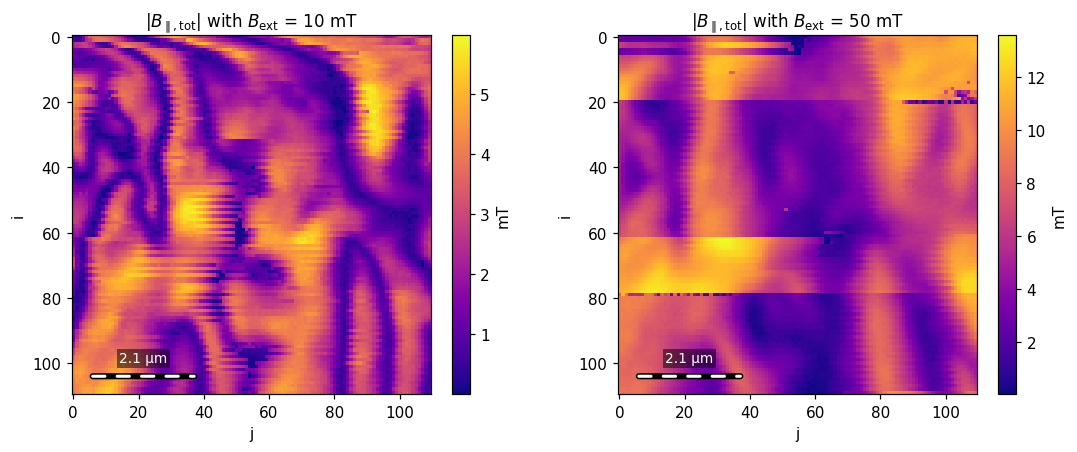

In [17]:
# Ajustement à un pic sur les deux cartes complètes, sans tracé des spectres individuels.
for date, scan in scans.items():
    rows = []
    f0 = np.full(scan['shape'], np.nan)
    for (i, j), sub in scan['df'].groupby(['i', 'j'], sort=True):
        x, y_raw, xf, yf, fit = fit_spectrum(sub, normalize=NORMALIZE, smooth_win=SMOOTH_WIN,
                                                D_Hz=D_HZ, crop_around_D=CROP_AROUND_D,
                                                keep_global_min=KEEP_GLOBAL_MIN)
        row = dict(i=int(i), j=int(j), success=fit['success'], reason=fit.get('reason', ''))
        if fit['success']:
            amp, center, width, baseline, slope = fit['popt']
            f0[int(i), int(j)] = center
            row.update(f0_Hz=center, FWHM_Hz=2*width, amplitude=amp,
                       rmse=float(np.sqrt(np.mean((yf - fit['yfit'])**2))),
                       edge_center=bool(min(center-xf.min(), xf.max()-center) < np.median(np.diff(xf))))
        rows.append(row)
    diagnostics = pd.DataFrame(rows)
    scan.update(f0_Hz=f0, A_mT=np.abs(f0 - D_HZ) / GAMMA_HZ_PER_T * 1e3,
                diagnostics=diagnostics)
    diagnostics.to_csv(OUT / ('fits_' + date + '.csv'), index=False)
    print(date, ':', diagnostics.success.sum(), '/', len(diagnostics), 'fits réussis ;',
          int(diagnostics.get('edge_center', pd.Series(dtype=bool)).fillna(False).sum()),
          'centres au bord de la fenêtre')

A = scans[DATE]['A_mT']
A_compare = scans[DATE_COMPARE]['A_mT']
valid_mask = np.isfinite(A)
assert valid_mask.any(), 'Aucun fit exploitable.'
meta = scans[DATE]['meta']
ny, nx = A.shape
Lx_m, Ly_m = map(float, meta['rect']['size'])
assert np.isclose(Lx_m/nx, Ly_m/ny), 'Le helper Fourier suppose des pixels carrés.'
dx_m = Lx_m/nx
Lx_um, Ly_um = Lx_m*1e6, Ly_m*1e6
z_meas_m = meta['scanHeightControl']['scanDistance']
print('Fraction valide :', valid_mask.mean(), '; pas spatial [nm] :', dx_m*1e9)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
plot_field(A*1e-3, title=r"$|B_{\parallel, \mathrm{tot}}|$ with $B_{\mathrm{ext}}$ = 10 mT",
           ax=axes[0], show=False, Size_um=Lx_um, scalebar=True, scalebar_frac=0.3)
plot_field(A_compare*1e-3, title=r"$|B_{\parallel, \mathrm{tot}}|$ with $B_\mathrm{ext}$ = 50 mT",
           ax=axes[1], show=False, Size_um=Lx_um, scalebar=True, scalebar_frac=0.3)
plt.show()

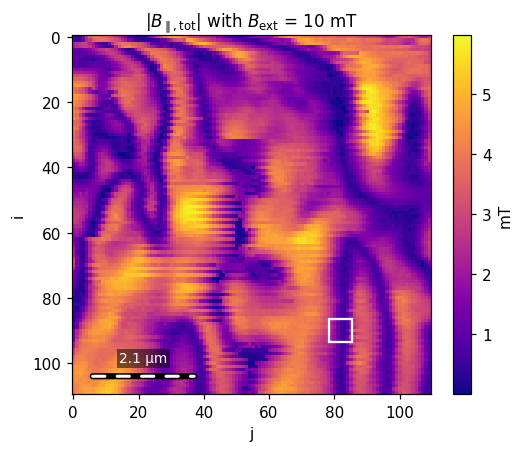

In [18]:
# affiche avec le carré blanc la roi des spectres montrés en exemple
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)

plot_field(A*1e-3, title=r"$|B_{\parallel,\mathrm{tot}}|$ with $B_{\mathrm{ext}}$ = 10 mT",
           ax=ax, show=False, Size_um=Lx_um, scalebar=True, scalebar_frac=0.3)

i0, i1, j0, j1 = roi_box
ax.add_patch(Rectangle((j0-0.5, i0-0.5), j1-j0+1, i1-i0+1,
                       fill=False, edgecolor='white', linewidth=1.5))

fig.savefig(OUT / 'scan_spectres_roi.png', dpi=200, bbox_inches='tight')
plt.show()

## 2. Annotation des seeds

L'initialisation commune crée un masque vide ou recharge un masque compatible
avec la date, la géométrie et la carte ajustée. Deux cellules alternatives
définissent ensuite les seeds : A pour l'annotation à la souris, B pour les
disques spécifiés par coordonnées. La dernière méthode exécutée détermine
le masque retenu lors de la validation commune. Un masque rechargé peut aussi
être validé directement sans nouvelle annotation.

Dans l'interface interactive, les clics gauche, droit et milieu correspondent
respectivement aux signes positif, négatif et à l'effacement. Les touches
`+`, `-`, `e` sélectionnent le mode ; `r` et `f` ajustent le rayon ; `c` efface
le masque. Les coordonnées sont exprimées dans le repère image transformé.
Les seeds représentent des hypothèses physiques locales sur le signe.

Public reproduction uses `SEED_MODE='saved'` by default. The immutable input is
`saved_seed_masks/seeds_2026-05-25-10-27-11.npz`; validation writes a separate copy
under `outputs/`. Select `coordinates` to use the listed disks. Select
`interactive` to edit the loaded mask with the mouse; pause after the annotation
cell before running validation. Running all cells without that pause is intended
only for the saved or coordinate modes.


In [19]:
seed_mask = osu.make_seed_mask(A)
seed_source = None
if INPUT_SEED_PATH.exists():
    with np.load(INPUT_SEED_PATH, allow_pickle=False) as saved:
        assert saved['date'].item() == DATE
        assert saved['seed_mask'].shape == A.shape
        assert np.allclose(saved['A_mT'], A, equal_nan=True), 'Carte modifiée : revalider les seeds.'
        seed_mask = saved['seed_mask'].copy()
    seed_source = 'loaded'
    print('Seeds rechargés :', INPUT_SEED_PATH)
assert SEED_MODE in ('saved', 'coordinates', 'interactive')


Seeds rechargés : c:\Users\herma\OneDrive\Bureau\Etudes EPFL\PDM\nv_reconstruction_public_share\saved_seed_masks\seeds_2026-05-25-10-27-11.npz


In [20]:
# Optional mouse annotation, initialized from the saved mask.
if SEED_MODE == 'interactive':
    get_ipython().run_line_magic('matplotlib', 'widget')
    annot = osu.SeedAnnotator(A, seed_mask=seed_mask, radius=4, show_status=True)
    seed_source = 'interactive'


In [21]:
if SEED_MODE == 'coordinates':
    # Cellule B : annotation des signes par disques en coordonnées image.
    from odmr_sign_unwrap import add_seed_disk
    
    # Initialisation indépendante du masque pour cette méthode.
    seed_mask = osu.make_seed_mask(A)
    seed_source = 'coordinates'
    
    # Positions, signes et rayons des disques de seeds.
    seed_mask = add_seed_disk(seed_mask, i=20, j=34, sign=+1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=50, j=38, sign=+1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=70, j=18, sign=+1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=95, j=44, sign=+1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=100, j=13, sign=+1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=105, j=46, sign=+1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=95, j=90, sign=+1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=20, j=93, sign=+1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=14, j=3, sign=+1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=30, j=15, sign=+1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=25, j=60, sign=-1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=65, j=70, sign=-1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=80, j=102, sign=-1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=100, j=70, sign=-1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=20, j=20, sign=-1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=50, j=2, sign=-1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=52, j=24, sign=-1, radius=1)
    seed_mask = add_seed_disk(seed_mask, i=101, j=34, sign=-1, radius=1)
    
    
    
    # Affichage statique du masque défini par coordonnées.
    if 'get_ipython' in globals() and get_ipython() is not None:
        get_ipython().run_line_magic('matplotlib', 'inline')
    osu.plot_seed_map(A, seed_mask)
    plt.show()


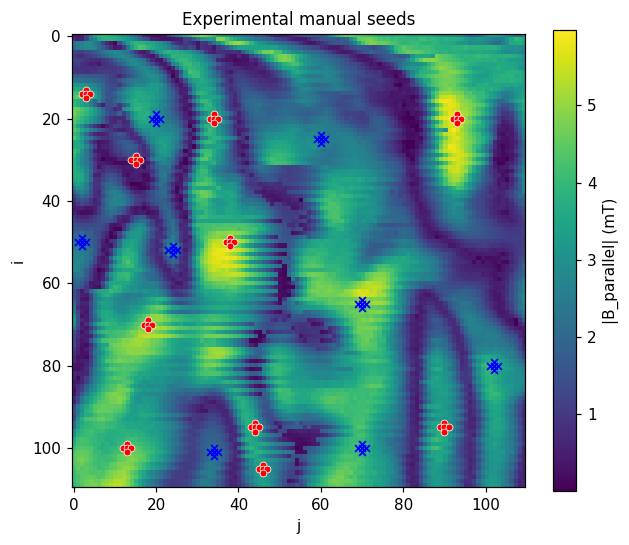

Seeds sauvegardés : c:\Users\herma\OneDrive\Bureau\Etudes EPFL\PDM\nv_reconstruction_public_share\outputs\sign_unwrap_2026-05-25-10-27-11\seeds_2026-05-25-10-27-11.npz


In [22]:
# Validation et sauvegarde du masque issu de la dernière méthode exécutée.
if seed_source == 'interactive':
    seed_mask = annot.seed_mask.copy()
    get_ipython().run_line_magic('matplotlib', 'inline')
assert seed_source in ('interactive', 'coordinates', 'loaded'), 'Aucune annotation ni masque rechargé disponible.'
assert seed_mask.shape == A.shape and np.isin(seed_mask, [-1, 0, 1]).all()
if np.any((seed_mask != 0) & ~valid_mask):
    warnings.warn('Seeds sur pixels invalides ignorés.')
seed_mask[~valid_mask] = 0
assert np.any(seed_mask == 1) and np.any(seed_mask == -1), 'Le masque doit contenir au moins une zone positive et une zone négative.'
np.savez_compressed(SEED_PATH, date=DATE, seed_mask=seed_mask.astype(np.int8), A_mT=A)
osu.plot_seed_map(A, seed_mask, title='Experimental manual seeds')
plt.savefig(OUT / 'seeds_experiment.pdf', bbox_inches='tight')
plt.show()
print('Seeds sauvegardés :', SEED_PATH)

## 3. Graph cut et raffinement continu

Le graph cut détermine une carte de signe en conservant exactement l'amplitude
mesurée A. Le raffinement continu peut modifier cette amplitude et impose
une pénalisation souple des seeds. La valeur `lambda_lap=0.53` contrôle le
lissage spatial ; sa variation permet d'évaluer la sensibilité du résultat
à la régularisation. Les diagnostics indiquent la convergence, la modification
RMS d'amplitude et les éventuels changements de signe sur les seeds.

Graph cut terminé.
  flow              = 68.4249
  scale_mT          = 4.62475
  pixels valides    = 12100
  arêtes            = 23980
  graines +         = 50
  graines -         = 40
  lambda_pair       = 1.0
  connectivité      = 4
Raffinement continu terminé.
  success       = True
  message       = CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  niter         = 118
  final energy  = 26.1076
  scale_mT      = 4.62475
  tau_mT        = 0.15
RMS modification amplitude [mT] = 0.2667625003988444
Seeds avec signe changé après raffinement = 0


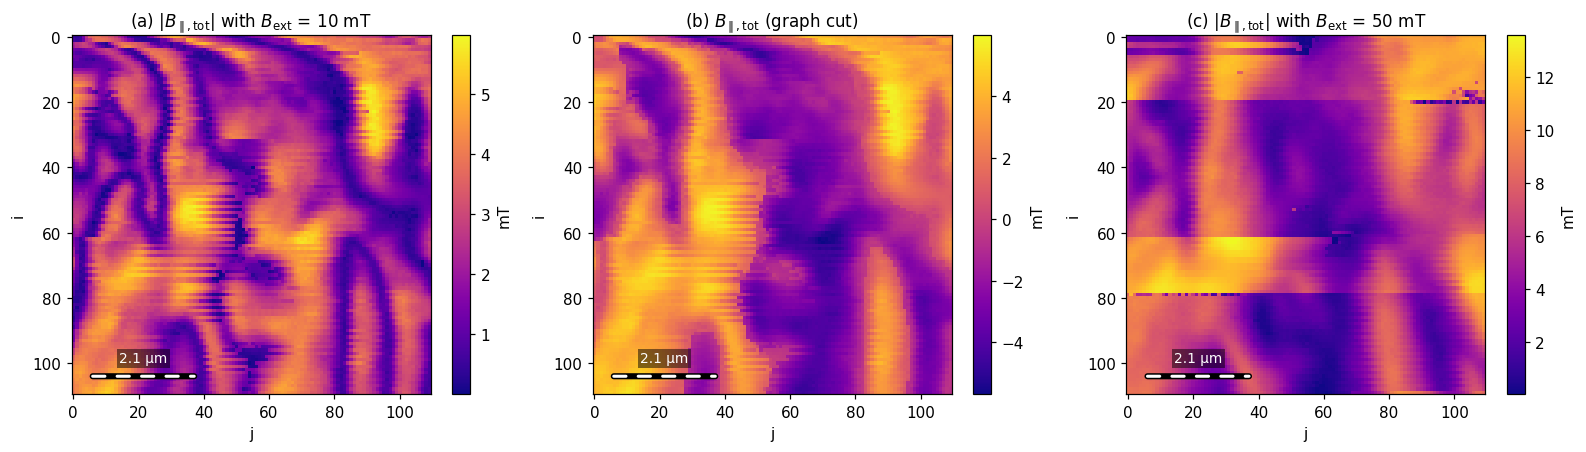

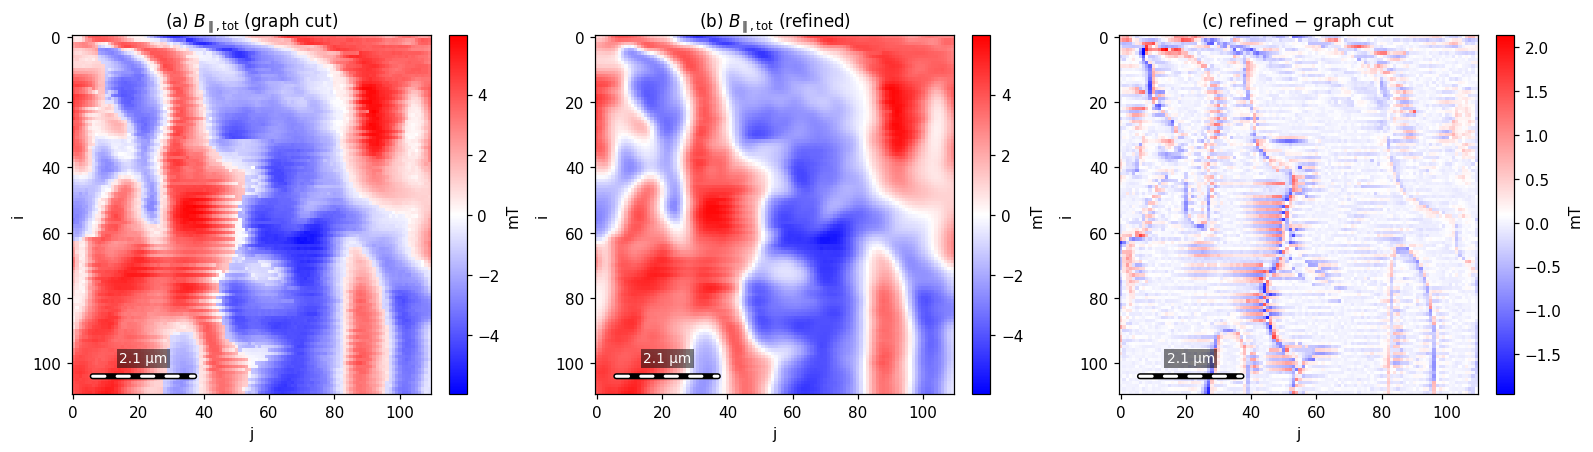

In [23]:
B_gc_mT, sign_gc, info_gc = osu.sign_unwrap_graphcut(
    A=A, seed_mask=seed_mask, valid_mask=valid_mask, **GC_KW)
assert np.allclose(np.abs(B_gc_mT[valid_mask]), A[valid_mask])
seeded = (seed_mask != 0) & valid_mask
assert np.array_equal(sign_gc[seeded], seed_mask[seeded])
B_ref_mT, info_ref = osu.refine_B_continuous(
    A=A, B_init=B_gc_mT, seed_mask=seed_mask, valid_mask=valid_mask, **REFINE_KW)
if not info_ref['success']:
    warnings.warn('Raffinement non convergé : ' + info_ref['message'])
print('RMS modification amplitude [mT] =',
      np.sqrt(np.nanmean((np.abs(B_ref_mT) - A)**2)))
print('Seeds avec signe changé après raffinement =',
      np.count_nonzero(np.sign(B_ref_mT[seeded]) != seed_mask[seeded]))

assert scans[DATE_COMPARE]['shape'] == A.shape
assert np.allclose(scans[DATE_COMPARE]['meta']['rect']['size'], meta['rect']['size'], rtol=1e-6, atol=1e-12)

fig, axes = plt.subplots(1, 3, figsize=(14.4, 4), constrained_layout=True)
plot_field(A*1e-3, title=r"(a) $|B_{\parallel, \mathrm{tot}}|$ with $B_{\mathrm{ext}}$ = 10 mT", show=False, ax=axes[0], Size_um=Lx_um, scalebar=True, scalebar_frac=0.3)
plot_field(B_gc_mT*1e-3, title=r"(b) $B_{\parallel, \mathrm{tot}}$ (graph cut)", show=False, ax=axes[1], cmap="plasma", Size_um=Lx_um, scalebar=True, scalebar_frac=0.3)
plot_field(A_compare*1e-3, title=r"(c) $|B_{\parallel, \mathrm{tot}}|$ with $B_\mathrm{ext}$ = 50 mT", show=False, ax=axes[2], Size_um=Lx_um, scalebar=True, scalebar_frac=0.3)
fig.savefig(
    OUT / "comparaison_B_parallel.pdf",
    bbox_inches="tight",
    facecolor="white",
)
fig.savefig(
    OUT / "comparaison_B_parallel.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14.4, 4), constrained_layout=True)
common_limit_mT = max(np.nanmax(np.abs(B_gc_mT)), np.nanmax(np.abs(B_ref_mT)))
plot_field(B_gc_mT*1e-3, title=r"(a) $B_{\parallel, \mathrm{tot}}$ (graph cut)", show=False, ax=axes[0], cmap="bwr", clim_mT=(-common_limit_mT, common_limit_mT), Size_um=Lx_um, scalebar=True, scalebar_frac=0.3)
plot_field(B_ref_mT*1e-3, title=r"(b) $B_{\parallel, \mathrm{tot}}$ (refined)", show=False, ax=axes[1], cmap="bwr", clim_mT=(-common_limit_mT, common_limit_mT), Size_um=Lx_um, scalebar=True, scalebar_frac=0.3)
plot_field((B_ref_mT-B_gc_mT)*1e-3, title=r"(c) refined $-$ graph cut ", show=False, ax=axes[2], cmap="bwr", Size_um=Lx_um, scalebar=True, scalebar_frac=0.3)
fig.savefig(
    OUT / "B_parallel_refined.pdf",
    bbox_inches="tight",
    facecolor="white",
)
fig.savefig(
    OUT / "B_parallel_refined.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

## 4. Reconstruction vectorielle et zooms

Le calcul utilise le repère image : x suit j et y suit i. L'affichage place
l'origine en haut à gauche. Les conventions de quiver, dont `flip_quiver_y=True`,
et les libellés suivent le workflow QZabre. L'axe NV supposé est exprimé dans
ce repère ; sa calibration indépendante conditionne l'interprétation physique.

L'inversion de Fourier utilise des champs en Tesla, un pas spatial en mètres
et la hauteur de mesure en mètres. Le mode uniforme k=0 est retiré car une
projection unique ne détermine pas trois composantes uniformes. Les cartes
reconstruites représentent les variations spatiales du champ.

Les pixels non finis sont interpolés au plus proche avant la FFT puis remasqués.
Cette interpolation et la périodicité implicite de la FFT peuvent introduire
des artefacts au voisinage des trous et des bords. Les flèches représentent
les composantes reconstruites et ne sont pas une mesure indépendante.

Axe NV supposé : [-0.81664156  0.          0.57714519] ; moyenne retirée [mT] : 0.26776273128729833


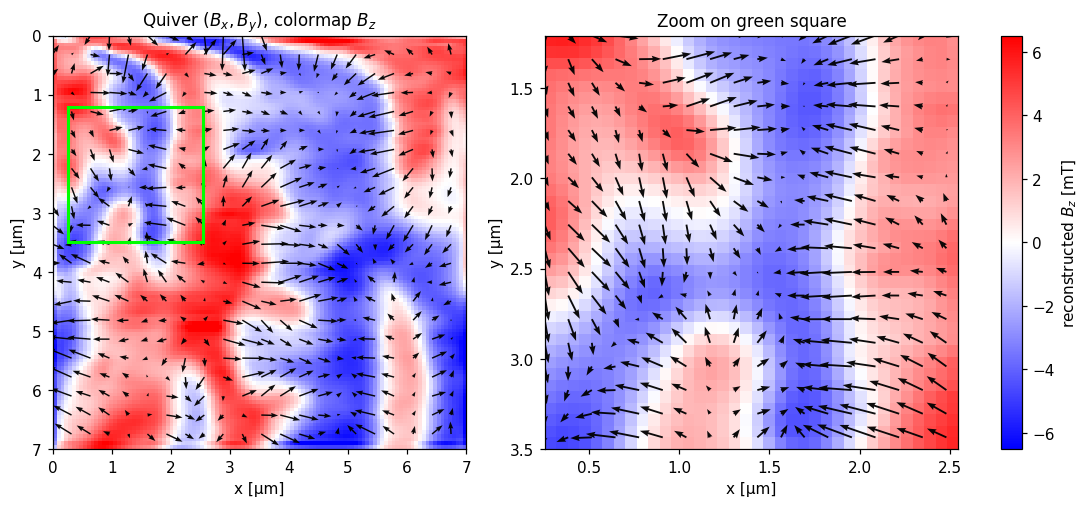

In [24]:
from helpers import nv_axis_in_image_frame
nv_axis = nv_axis_in_image_frame(NV_THETA_DEG, NV_PHI_DEG, IMAGE_AXIS_SIGNS)
Bpar_T = B_ref_mT * 1e-3
if not np.all(valid_mask):
    nearest = ndi.distance_transform_edt(~valid_mask, return_distances=False, return_indices=True)
    Bpar_T = Bpar_T[tuple(nearest)]
Bpar_mean_T = float(np.mean(Bpar_T))
B_rec = reconstruct_B_from_Bparallel_Fourier(
    Bpar_T=Bpar_T-Bpar_mean_T, nv_axis=nv_axis, dx=dx_m, d_meas=z_meas_m, **FOURIER_KW)
Bx_T, By_T, Bz_T = [np.where(valid_mask, component, np.nan) for component in B_rec]
print('Axe NV supposé :', nv_axis, '; moyenne retirée [mT] :', Bpar_mean_T*1e3)





Bx_rec, By_rec, Bz_rec = Bx_T, By_T, Bz_T

fig, axes, rect, im_full, im_zoom, q_full, q_zoom, roi = plot_reconstructed_B_quiver_with_zoom(
    figsize=(10, 4.5),
    Bx_T=Bx_rec,
    By_T=By_rec,
    Bz_T=Bz_rec,
    center_ij=(37,22), #(85, 40),
    side_px=35,
    extent=[0, Lx_um, 0, Ly_um],
    title_full=r"Quiver $(B_x, B_y)$, colormap $B_z$",
    title_zoom=r"Zoom on green square",
    cmap="bwr",
    clim_mT=None,
    clip_percentile=99.4, #None,      # None = pas de cutoff percentile
    symmetric=True,
    qstep_full=5,
    qstep_zoom=2,
    quiver_scale_full=0.09,
    quiver_scale_zoom=0.06,
    quiver_width_full=0.0035,
    quiver_width_zoom=0.0045,
    normalize_quiver=False,
    save_pdf=OUT / "Brec_full_and_zoom_quiver.pdf",
    save_png=OUT / "Brec_full_and_zoom_quiver.png",
    colorbar_label="reconstructed $B_z$ [mT]"
)

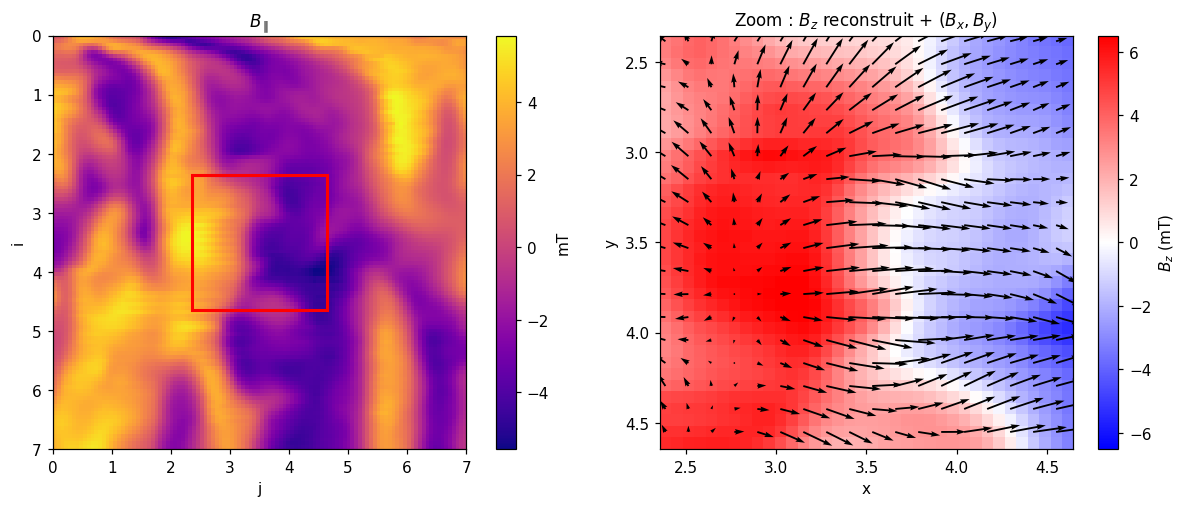

In [25]:
# Projection NV sur la carte entière et zoom du champ vectoriel reconstruit.
center_ij = (55, 55)
side_px = 36
ci, cj = center_ij
i0, i1 = max(0, ci-side_px//2), min(ny, ci+side_px//2)
j0, j1 = max(0, cj-side_px//2), min(nx, cj+side_px//2)
extent_zoom = [j0*dx_m*1e6, j1*dx_m*1e6, i1*dx_m*1e6, i0*dx_m*1e6]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
plot_field(B_ref_mT*1e-3, extent=[0,Lx_um,0,Ly_um], title=r"$B_\parallel$",
           ax=axes[0], show=False)
axes[0].add_patch(Rectangle((extent_zoom[0],extent_zoom[3]),
    extent_zoom[1]-extent_zoom[0], extent_zoom[2]-extent_zoom[3],
    fill=False, edgecolor='red', lw=2))
limit = max(float(np.nanpercentile(np.abs(Bz_T*1e3), 99.4)), 1e-12)
im = axes[1].imshow(Bz_T[i0:i1,j0:j1]*1e3, origin='upper', extent=extent_zoom,
                    cmap='bwr', vmin=-limit, vmax=limit, interpolation='nearest')
x = (np.arange(nx)+.5)*dx_m*1e6
y = (np.arange(ny)+.5)*dx_m*1e6
X, Y = np.meshgrid(x,y)
s = np.s_[i0:i1:2,j0:j1:2]
axes[1].quiver(X[s],Y[s],Bx_T[s],-By_T[s], scale=.06, width=.0045, color='k')
axes[1].set(title=r"Zoom : $B_z$ reconstruit + $(B_x, B_y)$", xlabel='x', ylabel='y')
fig.colorbar(im, ax=axes[1], label=r"$B_z$ (mT)")
for ext in ('pdf','png'):
    fig.savefig(OUT / ('Bpar_roi_zoom_quiver.'+ext), dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

In [26]:
# Export des résultats, du masque de validité et des paramètres de traitement.
provenance = dict(date=DATE, comparison_date=DATE_COMPARE, D_Hz=D_HZ,
                  gamma_Hz_per_T=GAMMA_HZ_PER_T, n_peaks=1,
                  normalize=NORMALIZE, smooth_win=SMOOTH_WIN,
                  crop_around_D=CROP_AROUND_D, keep_global_min=KEEP_GLOBAL_MIN,
                  seed_mode=seed_source, nv_axis=nv_axis.tolist(),
                  dx_m=dx_m, d_meas_m=z_meas_m, removed_mean_T=Bpar_mean_T,
                  image_axis_signs=IMAGE_AXIS_SIGNS, fourier_kwargs=FOURIER_KW,
                  graphcut_kwargs=GC_KW, refine_kwargs=REFINE_KW,
                  graphcut_info=info_gc, refine_info=info_ref)
np.savez_compressed(OUT / 'sign_unwrap_results.npz',
    A_mT=A, A_compare_mT=A_compare, B_gc_mT=B_gc_mT, B_ref_mT=B_ref_mT,
    seed_mask=seed_mask, valid_mask=valid_mask, Bx_T=Bx_T, By_T=By_T, Bz_T=Bz_T,
    provenance_json=json.dumps(provenance))
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
print('Résultats et figures :', OUT)

Résultats et figures : c:\Users\herma\OneDrive\Bureau\Etudes EPFL\PDM\nv_reconstruction_public_share\outputs\sign_unwrap_2026-05-25-10-27-11


### Coordinate convention

For these axis-aligned scans, the retained display indexing is i=j_raw,
j=Ni_raw-1-i_raw. The image coordinates increase rightwards and downwards;
instrument screenshots indicate X decreasing rightwards and Y increasing downwards.
Accordingly the instrument NV components are transformed by diag(-1,+1,+1)
before Fourier inversion. This assumption is explicit because the exported per-pixel
X/Y references are all NaN. A display inversion of y additionally reverses the
vertical arrow component; it does not rotate the data again. z points away from
the sample. A rotated scan would require a full coordinate transform.

The 50 mT map informed the experimental seeds and is not an independent validation.
The reconstructed field has zero mean and remains conditional on the NV calibration,
seed signs, single-peak ODMR approximation and coordinate convention.
